In [13]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
import random

In [14]:
ds = pd.read_csv('/kaggle/input/datasets/kingabzpro/zombies-apocalypse/zombies.csv')

In [15]:
cols = ds.columns
for col in cols:
    if (ds[col].dtype == 'object'):
        ds[col] = ds[col].astype('category')

In [16]:
model = XGBClassifier(enable_categorical=True)
encoder = LabelEncoder()
ds['zombie'] = encoder.fit_transform(ds['zombie'])

In [17]:
X = ds.drop(columns=['zombie', 'zombieid'])
y = ds['zombie']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=5)

In [18]:
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [19]:
pred = model.predict(X_test)

In [20]:
score = accuracy_score(y_test, pred)
print(score)

0.8787878787878788


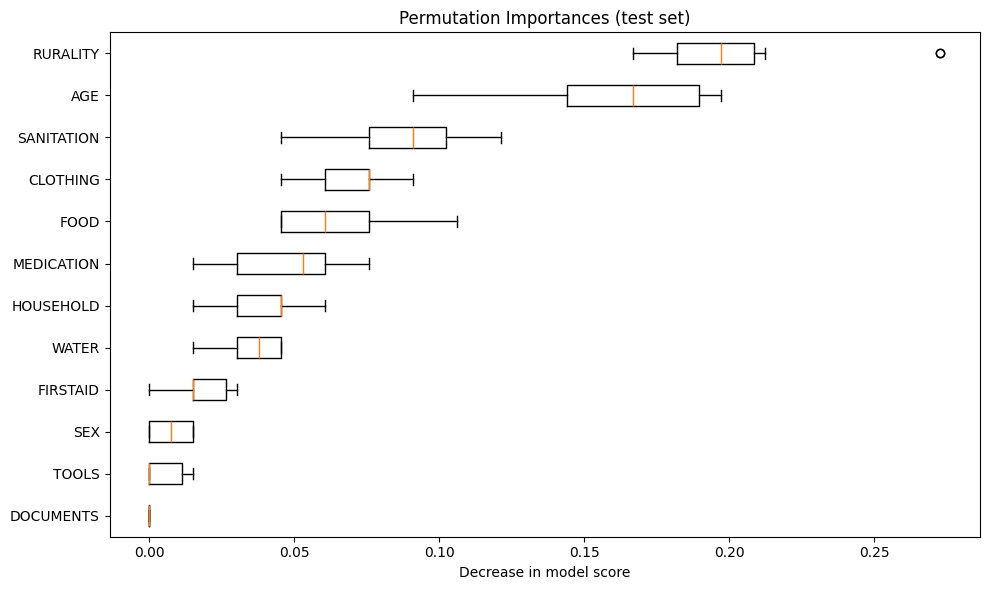

In [40]:
from sklearn.inspection import permutation_importance
n_run = 10
inspect = permutation_importance(model, X_test, pred, n_repeats=n_run, random_state=42)

feature_names = [f"{(X.columns[i]).upper()}" for i in range(inspect['importances'].shape[0])]

sorted_idx = inspect['importances_mean'].argsort()

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(
    inspect['importances'][sorted_idx].T,
    vert=False,
    tick_labels=np.array(feature_names)[sorted_idx]
)

ax.set_title("Permutation Importances (test set)")
ax.set_xlabel("Decrease in model score")
fig.tight_layout()
plt.show()